# Lives in space: birth → death places

Exploratory analysis of `birth_death_places_geo.csv` to prepare an **arc + map visualisation**
(one arc per person, from place of birth to place of death).

Questions: what is in the file, how many persons can actually be drawn as an arc, and how trustworthy are the coordinates?
The decisions taken here are implemented in [`build_map_json.py`](../src/data/build_map_json.py), which writes the JSON for the visualisation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd().parent / "src" / "data"))
import build_map_json as bm  # shared helpers: haversine, year parsing, suspect-place check

pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_rows(20)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

geo = bm.load_geo()
places = bm.load_places()
geo.head(3)

place_id,role,ark,person_label,lat,long
i64,i64,str,str,f64,f64
7090,1,"""https://ark.burgerbib.ch/ark:36599/00pgbn81p1g""","""Küpfer, Anna Magdalena (1851-1919)""",46.875225,7.7974921
8767,1,"""https://ark.burgerbib.ch/ark:36599/01cgvjrp45s""","""Pfenninger, Heinrich (1749-1815)""",47.374449,8.5410422
6775,2,"""https://ark.burgerbib.ch/ark:36599/01fx8x0q3g2""","""Zimmer, Johann Heinrich Ehrenfried (1774-1851)""",47.140208,7.2439029


## 1. Shape of the file
One row = one person × place × role (1 = birth, 2 = death).

In [2]:
print(f"rows: {geo.height}  persons: {geo['ark'].n_unique()}  places: {geo['place_id'].n_unique()}")
print("nulls:", geo.null_count().row(0))

# which role combinations does a person have? (e.g. '12' = one birth + one death place)
combos = (geo.group_by("ark").agg(pl.col("role").sort().cast(pl.String).str.join("").alias("roles"))
             ["roles"].value_counts().sort("count", descending=True))
combos

rows: 2895  persons: 1966  places: 561
nulls: (0, 0, 0, 0, 0, 0)


roles,count
str,u32
"""12""",918
"""1""",619
"""2""",422
"""11""",4
"""122""",1
"""112""",1
"""1122""",1


**Take-away:** only ~47% of persons (918 + a few multi-place cases) have *both* a birth and a death place.
The rest have just one, so they can be shown as points but not as arcs. A handful have several candidate places (`11`, `122`, `112`, `1122`).

In [3]:
persons = geo.group_by("ark").agg(
    (pl.col("role") == 1).any().alias("has_birth"), (pl.col("role") == 2).any().alias("has_death")
)
persons.group_by("has_birth", "has_death").len().sort("len", descending=True)

has_birth,has_death,len
bool,bool,u32
true,true,921
true,false,623
false,true,422


### Coverage against the full person–place relations
How many birth/death links of the archive are in this file?

In [4]:
d = bm.HERE
links = (pl.read_parquet(d / "persons_descriptors_places_descriptors.parquet")
           .filter(pl.col("role").is_in([1, 2]))
           .join(pl.read_parquet(bm.PLACES_PATH).select(pl.col("id").alias("id_place_descriptor"), "id_name", "label"), on="id_place_descriptor")
           .with_columns(pl.struct("id_name", "label").map_elements(lambda s: bm.place_country(s["id_name"], s["label"]), return_dtype=pl.String).eq("Schweiz (CH)").alias("swiss"))
           .with_columns(pl.col("id_place_descriptor").is_in(geo["place_id"].unique()).alias("in_file")))
print(f"archive: {links.height} birth/death links, {links['id_person_descriptor'].n_unique()} persons;  file: {geo.height} rows, {geo['ark'].n_unique()} persons")
links.group_by("swiss", "in_file").len().sort("swiss", "in_file")

archive: 4264 birth/death links, 2742 persons;  file: 2895 rows, 1966 persons


/var/folders/bz/k4tzhqk96xvgd4czxy1xvcgh0000gn/T/ipykernel_94583/1313323118.py:6: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  .with_columns(pl.col("id_place_descriptor").is_in(geo["place_id"].unique()).alias("in_file")))


swiss,in_file,len
bool,bool,u32
false,false,1355
false,true,20
true,false,11
true,true,2878


**Take-away:** the file covers almost every *Swiss* place (2,878 of 2,889 links) but practically **no foreign places** (20 of 1,375 links).
About 1,355 birth/death links, roughly a third of the archive's, sit on non-Swiss descriptors without coordinates,
so ~98% of the arcs are currently Swiss-internal. The long-distance arcs the visualisation would be most interesting for are the ones still missing.

## 2. Places: a few hubs dominate

top 5 places = 46% of all rows; 330 of 561 places appear only once


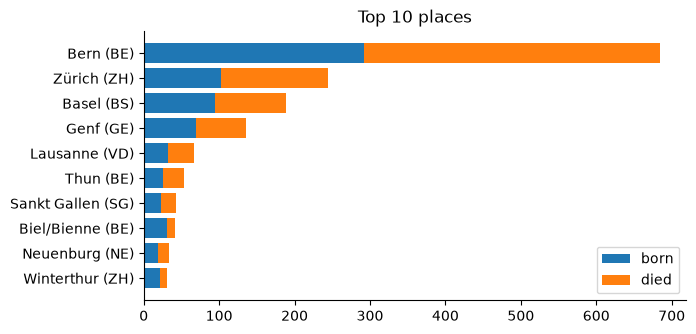

In [5]:
by_place = (geo.group_by("place_id").agg((pl.col("role") == 1).sum().alias("births"), (pl.col("role") == 2).sum().alias("deaths"))
              .with_columns((pl.col("births") + pl.col("deaths")).alias("total"))
              .join(places.select("place_id", "label", "country"), on="place_id")
              .sort("total", descending=True))
top = by_place.head(10)
print(f"top 5 places = {by_place['total'].head(5).sum() / geo.height:.0%} of all rows; "
      f"{(by_place['total'] == 1).sum()} of {by_place.height} places appear only once")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(top["label"][::-1], top["births"][::-1], label="born")
ax.barh(top["label"][::-1], top["deaths"][::-1], left=top["births"][::-1], label="died")
ax.set_title("Top 10 places"); ax.legend(); plt.show()

**Take-away:** Bern alone accounts for ~24% of rows and the top 5 places for 46%, while 330 of 561 places appear only once.
Arcs will converge on a few hubs, so aggregated flows (origin → destination with a count) are worth shipping next to the per-person arcs.

## 3. Geocoding quality
The place descriptors carry their hierarchy (`Orte\Sch\Schweiz (CH)\…`). Any place that is *Swiss by descriptor* but lies outside a
bounding box around Switzerland is certainly a geocoding error (OSM matched a homonym).

country of descriptor:
shape: (5, 2)
┌────────────────────┬───────┐
│ country            ┆ count │
│ ---                ┆ ---   │
│ str                ┆ u32   │
╞════════════════════╪═══════╡
│ Schweiz (CH)       ┆ 550   │
│ Griechenland (GRC) ┆ 2     │
│ Ägypten (ET)       ┆ 2     │
│ Algerien (DZ)      ┆ 1     │
│ Libanon (LBN)      ┆ 1     │
└────────────────────┴───────┘
48 of 561 places are suspect, affecting 112 rows (3.9%) and 95 persons


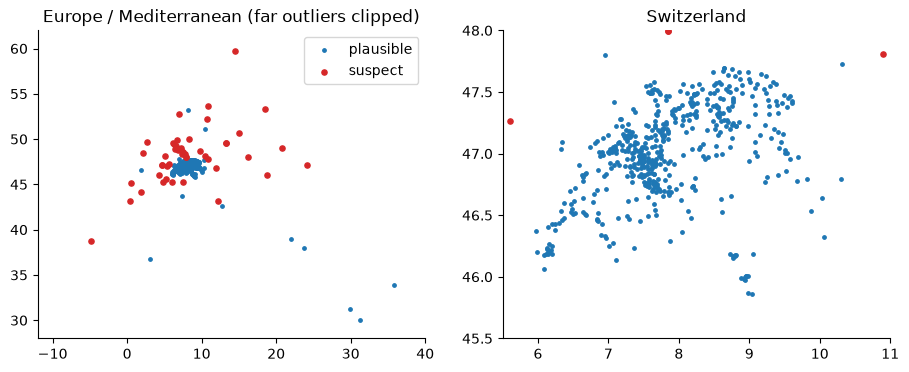

place_id,label,id_name,lat,lon
i64,str,str,f64,f64
6614,"""Altdorf (UR)""","""Altdorf (UR) (Orte\Sch\Schweiz (CH)\Uri (Kanton))""",48.522999,7.5271687
6679,"""Baar (ZG)""","""Baar (ZG) (Orte\Sch\Schweiz (CH)\Zug (Kanton))""",46.051814,18.71725
6691,"""Baden (AG)""","""Baden (AG) (Orte\Sch\Schweiz (CH)\Aargau (Kanton))""",48.007671,16.234369
6745,"""Berg (TG)""","""Berg (TG) (Orte\Sch\Schweiz (CH)\Thurgau (Kanton))""",49.43077,6.3111933
6782,"""Binningen (BL)""","""Binningen (BL) (Orte\Sch\Schweiz (CH)\Basel-Landschaft (Kant…",49.036974,7.2516945
6940,"""Chaumont""","""Chaumont (Orte\Sch\Schweiz (CH)\Neuenburg (Kanton)\Val-de-Ru…",48.111132,5.1395849
6952,"""Chillon""","""Chillon (Orte\Sch\Schweiz (CH)\Waadt (Kanton)\Veytaux (VD))""",38.796752,-4.866912
6958,"""Clarens""","""Clarens (Orte\Sch\Schweiz (CH)\Waadt (Kanton)\Montreux (VD))""",43.162857,0.4147041
6970,"""Colombier""","""Colombier (Orte\Sch\Schweiz (CH)\Neuenburg (Kanton)\Milvigne…",47.16917,4.6741844


In [6]:
print("country of descriptor:"); print(places["country"].value_counts().sort("count", descending=True).head(5))
suspect = places.filter("suspect")
affected = geo.join(suspect.select("place_id"), on="place_id")
print(f"{suspect.height} of {places.height} places are suspect, affecting {affected.height} rows "
      f"({affected.height / geo.height:.1%}) and {affected['ark'].n_unique()} persons")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, (xl, yl) in zip((a1, a2), (((-12, 40), (28, 62)), ((5.5, 11), (45.5, 48)))):
    ok = places.filter(~pl.col("suspect")); bad = suspect
    ax.scatter(ok["lon"], ok["lat"], s=6, c="tab:blue", label="plausible")
    ax.scatter(bad["lon"], bad["lat"], s=14, c="tab:red", label="suspect")
    ax.set_xlim(xl); ax.set_ylim(yl)
a1.set_title("Europe / Mediterranean (far outliers clipped)"); a2.set_title("Switzerland"); a1.legend(); plt.show()

suspect.select("place_id", "label", "id_name", "lat", "lon").sort("label").head(12)

In [7]:
# The most-used suspect places (these cost the most arcs)
(affected.group_by("place_id").len().join(suspect.select("place_id", "id_name"), on="place_id")
         .sort("len", descending=True).head(8))

place_id,len,id_name
i64,u32,str
7205,24,"""Freiburg (FR) (Orte\Sch\Schweiz (CH)\Freiburg (Kanton))"""
6691,9,"""Baden (AG) (Orte\Sch\Schweiz (CH)\Aargau (Kanton))"""
7666,6,"""L'Isle (VD) (Orte\Sch\Schweiz (CH)\Waadt (Kanton))"""
6970,4,"""Colombier (Orte\Sch\Schweiz (CH)\Neuenburg (Kanton)\Milvigne…"
6971,4,"""Colombier (Orte\Sch\Schweiz (CH)\Waadt (Kanton)\Echichens (V…"
7508,4,"""Kirchdorf (BE) (Orte\Sch\Schweiz (CH)\Bern (Kanton))"""
8392,4,"""Sankt Stephan (BE) (Orte\Sch\Schweiz (CH)\Bern (Kanton))"""
6614,3,"""Altdorf (UR) (Orte\Sch\Schweiz (CH)\Uri (Kanton))"""


**Take-away:** 48 places (~9% of places, 4% of rows, 95 persons) are wrongly geocoded (e.g. *Mullen* → Nebraska, *Chillon* → Spain, *Widen* → Sweden, *Freiburg (FR)* → Freiburg im Breisgau).
They include real hubs such as Freiburg (24 rows) and Baden, so fixing them is worthwhile for the Burgerbibliothek.
For the visualisation these places are **flagged and excluded by default** (`--keep-suspect` to override).
A plausible-looking but wrong location *inside* Switzerland (wrong canton) cannot be caught with this check, and non-Swiss places have no check at all.

## 4. Arcs: distance, same-place and multiple candidates

In [8]:
data = bm.build(keep_suspect=True)           # keep everything here to quantify it
arcs = pl.DataFrame(data["arcs"])
print({k: v for k, v in data["meta"].items() if k.startswith(("persons", "skipped", "n_arcs"))})
print(f"ambiguous persons (several birth/death places): {arcs.filter('ambiguous')['ark'].n_unique()}")

{'n_arcs': 557, 'persons': 1966, 'persons_with_arc_candidate': 921, 'skipped_suspect': 0, 'skipped_same_place': 369}
ambiguous persons (several birth/death places): 2


shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 518.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 71.37529   │
│ std        ┆ 179.837288 │
│ min        ┆ 1.2        │
│ 25%        ┆ 18.7       │
│ 50%        ┆ 39.8       │
│ 75%        ┆ 84.3       │
│ max        ┆ 2801.7     │
└────────────┴────────────┘


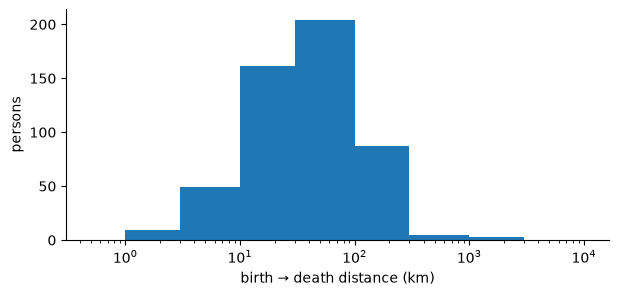

name,birth_year,death_year,source,target,distance_km
str,i64,i64,i64,i64,f64
"""Burckhardt, Johann Ludwig (1784-1817)""",1784,1817,7601,965,2801.7
"""Dürler, Jost (1745-1802)""",1745,1802,7715,847,2548.1
"""Geiser, Jean (1848-1923)""",1848,1923,7557,848,1189.9
"""Müller, Eduard (1820-1900)""",1820,1900,913,6752,517.0
"""Ryssel, Carl Viktor (1849-1905)""",1849,1905,913,8767,443.4
"""Michaud, Eugène (1839-1917)""",1839,1917,933,6752,425.3
"""Boiceau, Ernest-Jacques (1881-1950)""",1881,1950,7601,933,362.8
"""Carl, Jean (1877-1944)""",1877,1944,8307,7235,324.7
"""Geisser, Jean-Joseph (1824-1894)""",1824,1894,6619,7601,240.4


In [9]:
clean = pl.DataFrame(bm.build(keep_suspect=False)["arcs"])
print(clean["distance_km"].describe())

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(clean["distance_km"], bins=[0.5, 1, 3, 10, 30, 100, 300, 1000, 3000, 10000], color="tab:blue")
ax.set_xscale("log"); ax.set_xlabel("birth → death distance (km)"); ax.set_ylabel("persons"); plt.show()

clean.sort("distance_km", descending=True).select("name", "birth_year", "death_year", "source", "target", "distance_km").head(10)

**Take-away:** of 921 persons with both places, ~350 were born and died in the same place (distance < 0.5 km) and give no visible arc.
After dropping those and the suspect places, 518 arcs remain. The median is 40 km, 95 arcs exceed 100 km and only 8 exceed 300 km
(the longest are to Cairo and Alexandria). 511 of the 518 are Swiss-internal.
The distribution is heavily skewed, so use a log or capped scale for width/colour in the viewer.

## 5. Time: can we add a time slider?
Years are parsed from the label, e.g. `(1679-1767)`. Partial dates such as `19??`, `belegt …` or `?` give no year.

birth year known: 99%, death year known: 100%


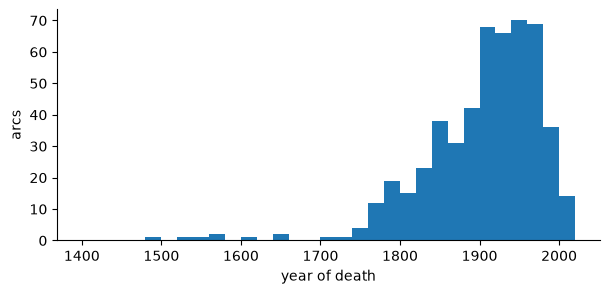

In [10]:
n = clean.height
print(f"birth year known: {clean['birth_year'].is_not_null().sum() / n:.0%}, death year known: {clean['death_year'].is_not_null().sum() / n:.0%}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(clean["death_year"].drop_nulls(), bins=range(1400, 2040, 20)); ax.set_xlabel("year of death"); ax.set_ylabel("arcs"); plt.show()

**Take-away:** 99% of arcs have a birth year and 100% a death year. The median death year is 1919 (10th percentile 1808, 90th 1977; only 8 arcs before 1700),
so a time slider or colour by period is feasible but will mostly cover the 19th–20th century.

## 6. Decisions implemented in `build_map_json.py`
| Topic | Decision |
|---|---|
| Arc definition | one arc per person = birth place → death place; persons with several candidates get one arc per pair, flagged `ambiguous` |
| Persons with one place only | no arc; they appear only in the `places` point layer (`births` / `deaths` counts) |
| Same place | arcs < 0.5 km dropped (counted in `meta.skipped_same_place`) |
| Wrong coordinates | Swiss descriptors outside the Swiss bounding box → `suspect`, excluded from places/arcs (`--keep-suspect` to keep) |
| Output | `places`, `arcs` (deck.gl-friendly `from`/`to` = `[lon, lat]`), aggregated `flows`, and `meta` |
| Years | parsed from the label, `null` if unknown |

Run: `python src/data/build_map_json.py` → `src/data/map_data.json`

In [11]:
out = bm.DEFAULT_OUT
import json
out.write_text(json.dumps(bm.build(), ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
print(out, f"{out.stat().st_size / 1024:.0f} kB")

/Users/mromanello/Documents/GLAMHack2026/GLAMHACK26-BurgerBib-LivesInSpace/data/src/data/map_data.json 215 kB
